# ANN for satellite patches: urban vs. forest

## 0. Setup

In [55]:
import os, random, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hides TensorFlow's INFO/WARNING chatter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, ConfusionMatrixDisplay

import tensorflow as tf
import tifffile

Image.MAX_IMAGE_PIXELS = None   # erases the pixel limit of Image

# ----------------------------- configuration ------------------------------
DATA_DIR       = "data"                 # data/urban/*.tiff  and  data/forest/*.tiff
CLASSES        = ["forest", "urban"]    # tag 0 = forest, tag 1 = urban
PATCH          = 200                    # patch size in pixels
STRIDE         = 200                    # = PATCH -> patches do not overlap
TEST_FRACTION  = 0.30                   # right-hand 30 % of every image is kept for the test phase
VAL_FRACTION   = 0.20                   # of the remaining 70 %, used for validation
MAX_PER_CLASS  = 600                    # cap on training+validation patches per class (memory)
EPOCHS         = 40
PATIENCE       = 10                     # early stopping on validation loss
BATCH          = 32
N_SEEDS        = 3                      # repeat every experiment with different random weights
SEED           = 50

def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)

set_seed(SEED)
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Posing the task as a function

The function mapping an input to an output:

$$ f:\; \mathbf{x} \in \{0,\dots,255\}^{200\times 200\times 3} \;\longrightarrow\; y \in \{0,1\} $$

* **Input $\mathbf{x}$** – one patch: 200 × 200 pixels × 3 colour bands (red, green, blue) = 120 000 numbers.
* **Output $y$** – the **tag**: 0 = forest, 1 = urban. In practice the ANN outputs a number $p = P(\text{urban}\mid \mathbf{x}) \in (0,1)$. The patch is urban if $p > 0.5$.

$f$ cannot be written down as a formula, but we can collect examples $(\mathbf{x}_i, y_i)$ where the answer is known. A neural network is a flexible, parametrised function $f_{\mathbf{w}}$, and training means finding the weights $\mathbf{w}$ that make $f_{\mathbf{w}}(\mathbf{x}_i) \approx y_i$.

| ML term | In this lab |
|---|---|
| **Feature** | the pixel values of one patch (200 × 200 × 3) |
| **Label / tag** | 0 = forest, 1 = urban |
| **Example** | one (patch, tag) pair |
| **Training phase** | learn $\mathbf{w}$ from patches with known tags |
| **Test phase** | feed new patches and compare the predicted tag with the truth |

## 2. Creating the training data

Steps:

1. **Load** every image in `data/<class>/`.
2. **Cut** it into non-overlapping 200 × 200 patches. Each patch inherits the tag of the folder it came from. Patches with nodata borders or saturated white pixels are discarded.
3. **Split without leaking.** Neighbouring patches look very much alike, so a random split of all patches would put near-copies in both train and test and give over-optimistic scores. So instead the split is spatial: the left 70 % of each image feeds training + validation, the right 30 % is the test set and is never touched until the final evaluation.
4. **Balance** the classes (same number of urban and forest patches) so that accuracy is meaningful.

The data used is a collection of 8-bit TIFF images gathered from Copernicus Browser.

In [56]:
def list_images(folder):
    # Return a sorted list of all .tiff files in the folder.
    folder = Path(folder)
    return sorted(p for p in folder.glob("*") if p.suffix.lower() == ".tiff") if folder.exists() else []

def load_image(path):
    # Return (rgb uint8 [H,W,3], valid-pixel mask [H,W]).
    path = Path(path)
    arr = tifffile.imread(str(path))
    if arr.ndim == 3 and arr.shape[0] < arr.shape[-1]:      # (bands,H,W) -> (H,W,bands)
        arr = np.moveaxis(arr, 0, -1)
    if arr.ndim == 2:                                            # grayscale -> 3 channels
        arr = np.repeat(arr[..., None], 3, axis=-1)
    if arr.shape[-1] > 4:
        warnings.warn(f"{path.name}: {arr.shape[-1]} bands, using the first 3 as RGB")
    valid = arr[..., 3] > 0 if arr.shape[-1] == 4 else np.ones(arr.shape[:2], bool)   # alpha = nodata
    arr = arr[..., :3]
    valid &= arr.any(axis=-1)                                    # pure black = nodata
    return arr, valid

def patch_ok(p, m):
    # Return True if the patch p is valid (not nodata, not saturated).
    if m.mean() < 0.98:                       # nodata border
        return False
    if p.mean() > 215 and p.std() < 25:       # saturated flat white: cloud / snow
        return False
    return True

def sample_patches(img, valid, x_range, cap, rng):
    # Random non-overlapping PATCH x PATCH tiles from columns x_range of the image.
    H, _, _ = img.shape
    x0, x1 = x_range
    coords = [(y, x) for y in range(0, H - PATCH + 1, STRIDE)
                     for x in range(x0, x1 - PATCH + 1, STRIDE)]
    rng.shuffle(coords)
    out = []
    for y, x in coords:
        if len(out) >= cap:
            break
        p = img[y:y + PATCH, x:x + PATCH]
        if patch_ok(p, valid[y:y + PATCH, x:x + PATCH]):
            out.append(p)
    return out

for c in CLASSES:
    print(f"{c:7s}:", [p.name for p in list_images(Path(DATA_DIR) / c)])

forest : ['forest1.tiff', 'forest2.tiff', 'forest3.tiff', 'forest4.tiff', 'forest5.tiff']
urban  : ['urban1.tiff', 'urban2.tiff', 'urban3.tiff', 'urban4.tiff', 'urban5.tiff']


In [57]:
def build_dataset(data_dir):
    # Return ((X_trainval, y_trainval), (X_test, y_test)) with balanced classes.
    rng = np.random.default_rng(SEED)
    max_test = int(MAX_PER_CLASS * TEST_FRACTION / (1 - TEST_FRACTION))
    tv = {c: [] for c in range(len(CLASSES))}
    te = {c: [] for c in range(len(CLASSES))}
    for label, cls in enumerate(CLASSES):
        files = list_images(Path(data_dir) / cls)
        for f in files:
            img, valid = load_image(f)
            split = int(img.shape[1] * (1 - TEST_FRACTION))     # train | test boundary (column)
            a = sample_patches(img, valid, (0, split),            int(np.ceil(MAX_PER_CLASS / len(files))), rng)
            b = sample_patches(img, valid, (split, img.shape[1]), int(np.ceil(max_test / len(files))), rng)
            tv[label] += a; te[label] += b
            print(f"{cls:7s} {f.name:25s} {img.shape[1]}x{img.shape[0]} px -> {len(a):4d} train/val, {len(b):4d} test patches")
            del img, valid
    def balance(pool, name):
        # Return (X, y) with balanced classes from the pool of patches.
        n = min(len(v) for v in pool.values())
        X, y = [], []
        for label, patches in pool.items():
            idx = rng.choice(len(patches), n, replace=False)
            X += [patches[i] for i in idx]; y += [label] * n
        X = np.stack(X); y = np.array(y)
        p = rng.permutation(len(y))
        return X[p], y[p]
    return balance(tv, "train/val"), balance(te, "test")

(X_tv, y_tv), (X_te, y_te) = build_dataset(DATA_DIR)
X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=VAL_FRACTION, stratify=y_tv, random_state=SEED)

print(f"\ntrain: {X_tr.shape}  val: {X_va.shape}  test: {X_te.shape}")
print("patches per class  train:", np.bincount(y_tr), " val:", np.bincount(y_va), " test:", np.bincount(y_te))

forest  forest1.tiff              1309x1314 px ->   24 train/val,    6 test patches
forest  forest2.tiff              1192x1158 px ->   20 train/val,    5 test patches
forest  forest3.tiff              1756x1725 px ->   48 train/val,   16 test patches
forest  forest4.tiff              1376x1254 px ->   24 train/val,   12 test patches
forest  forest5.tiff              1521x1452 px ->   35 train/val,   14 test patches
urban   urban1.tiff               1112x1084 px ->   15 train/val,    5 test patches
urban   urban2.tiff               1294x1217 px ->   24 train/val,    6 test patches
urban   urban3.tiff               1017x1009 px ->   15 train/val,    5 test patches
urban   urban4.tiff               1001x1007 px ->   15 train/val,    5 test patches
urban   urban5.tiff               1124x1119 px ->   15 train/val,    5 test patches

train: (134, 200, 200, 3)  val: (34, 200, 200, 3)  test: (52, 200, 200, 3)
patches per class  train: [67 67]  val: [17 17]  test: [26 26]


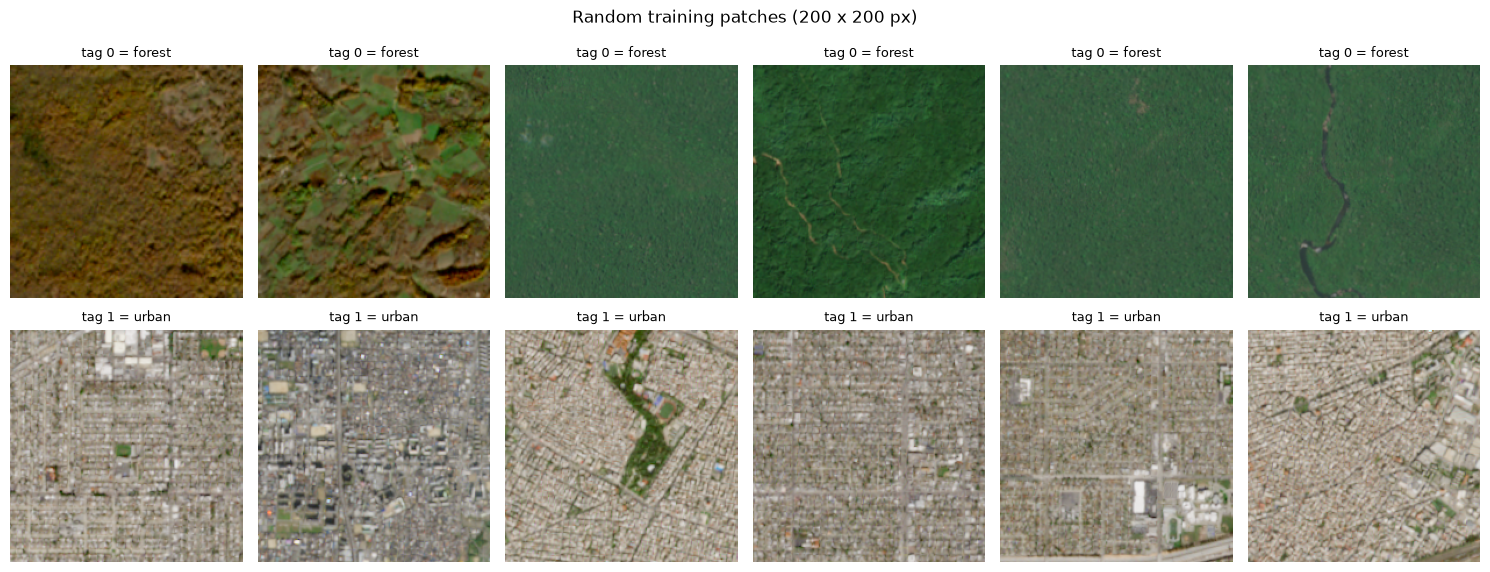

In [58]:
# show random training patches
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
rng_v = np.random.default_rng(0)
for r, label in enumerate(range(len(CLASSES))):
    idx = rng_v.choice(np.where(y_tr == label)[0], 6, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_tr[i]); axes[r, c].axis("off")
        axes[r, c].set_title(f"tag {label} = {CLASSES[label]}", fontsize=9)
plt.suptitle("Random training patches (200 x 200 px)")
plt.tight_layout(); plt.show()

### Quick look at the data

A scatter of mean brightness vs. edge strength showing whether the two classes are separable by eye.

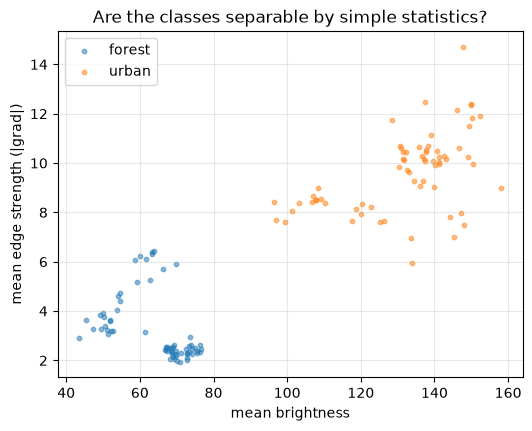

In [59]:
def quick_stats(X):
    # Return (mean brightness, mean edge strength) for each patch in X.
    g = X.astype(np.float32).mean(-1)
    bright = g.mean((1, 2))
    edges = (np.abs(np.diff(g, axis=2)).mean((1, 2)) + np.abs(np.diff(g, axis=1)).mean((1, 2))) / 2
    return bright, edges

b, e = quick_stats(X_tr)
plt.figure(figsize=(6, 4.5))
for label in range(len(CLASSES)):
    plt.scatter(b[y_tr == label], e[y_tr == label], s=10, alpha=.5, label=CLASSES[label])
plt.xlabel("mean brightness"); plt.ylabel("mean edge strength (|grad|)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Are the classes separable by simple statistics?"); plt.show()

## 3. Baseline ANN

Bare-bones architecture: flattened 200×200×3 input → 1 hidden Dense layer (16 ReLU neurons) → 1 sigmoid output neuron; binary cross-entropy loss, Adam optimiser. One output neuron suffices because there are only two classes, and one non-linear hidden layer is the minimum needed to go beyond a linear classifier, according to the universal approximation theorem.

In [60]:
L = tf.keras.layers

def make_optimizer(name, lr):
    # Return a compiled optimizer from its name and learning rate.
    return {"adam":         lambda: tf.keras.optimizers.Adam(lr),
            "sgd":          lambda: tf.keras.optimizers.SGD(lr),
            "sgd_momentum": lambda: tf.keras.optimizers.SGD(lr, momentum=0.9),
            "rmsprop":      lambda: tf.keras.optimizers.RMSprop(lr)}[name]()

def build_model(cfg):
    # Return a compiled Keras model according to the configuration dictionary cfg.
    inp = L.Input(shape=(PATCH, PATCH, 3), dtype="uint8")
    x = L.Rescaling(1 / 255.)(inp)                       # 0..255 -> 0..1
    if cfg.get("pool"):
        x = L.AveragePooling2D(cfg["pool"])(x)           # fixed (non-learned) down-sampling
    x = L.Flatten()(x)
    reg = tf.keras.regularizers.l2(cfg["l2"]) if cfg.get("l2") else None
    for n in cfg["hidden"]:
        x = L.Dense(n, activation=cfg.get("act", "relu"), kernel_regularizer=reg)(x)
        if cfg.get("dropout"):
            x = L.Dropout(cfg["dropout"])(x)
    out = L.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inp, out)
    model.compile(loss="binary_crossentropy", optimizer=make_optimizer(cfg["opt"], cfg["lr"]), metrics=["accuracy"])
    return model

def acc(model, X, y):
    # Return the accuracy of the model on the dataset (X, y).
    return float(np.mean((model.predict(X, verbose=0).ravel() > 0.5) == y))

def run_experiment(cfg, seed):
    # Run a single experiment with the given configuration and random seed, returning a dictionary of results.
    set_seed(seed); tf.keras.backend.clear_session()
    model = build_model(cfg)
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH, callbacks=[es], verbose=0)
    secs = time.time() - t0
    p_te = model.predict(X_te, verbose=0).ravel()
    return dict(model=model, history=hist.history, secs=secs,
                params=model.count_params(), epochs=len(hist.history["loss"]),
                train_acc=acc(model, X_tr, y_tr), val_acc=acc(model, X_va, y_va),
                test_acc=float(np.mean((p_te > 0.5) == y_te)),
                test_f1=f1_score(y_te, p_te > 0.5), p_test=p_te)

## 4. Single run baseline check

parameters: 1,920,033   epochs run: 27   time: 7s
accuracy  train 1.000 | val 1.000 | TEST 1.000   (test F1 1.000)


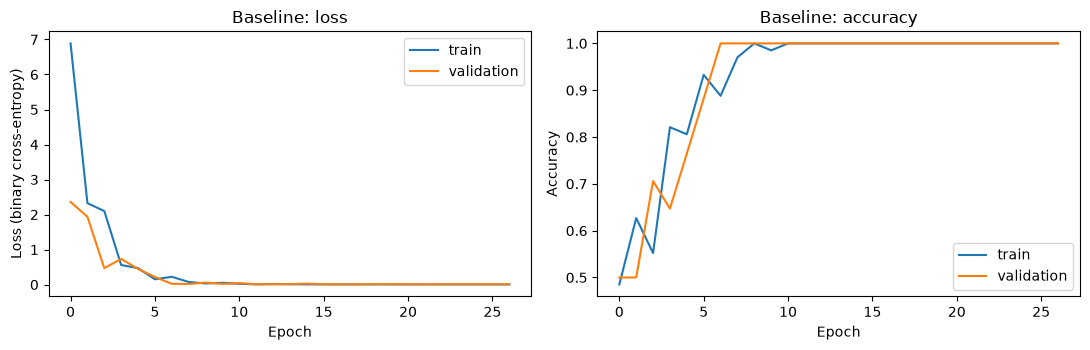

In [61]:
baseline_cfg = dict(name="E1 baseline: 16 ReLU, Adam", hidden=[16], opt="adam", lr=1e-3)
r = run_experiment(baseline_cfg, SEED)

print(f"parameters: {r['params']:,}   epochs run: {r['epochs']}   time: {r['secs']:.0f}s")
print(f"accuracy  train {r['train_acc']:.3f} | val {r['val_acc']:.3f} | TEST {r['test_acc']:.3f}   (test F1 {r['test_f1']:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(r["history"]["loss"], label="train"); ax[0].plot(r["history"]["val_loss"], label="validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss (binary cross-entropy)"); ax[0].legend(); ax[0].set_title("Baseline: loss")
ax[1].plot(r["history"]["accuracy"], label="train"); ax[1].plot(r["history"]["val_accuracy"], label="validation")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend(); ax[1].set_title("Baseline: accuracy")
plt.tight_layout(); plt.show()

## 5. Seven permutations

Each experiment changes one thing relative to the baseline (E1), so that differences can be attributed properly. Because the weights start random, a single run can be lucky or unlucky. Each configuration is therefore repeated with `N_SEEDS` seeds with a reported mean ± std.

| # | What changes | Reason |
|---|---|---|
| E1 | **baseline**: 1 × 16 ReLU, Adam | reference |
| E2 | **more nodes** (128) | more capacity |
| E3 | **more layers** (128 → 64 → 32) | deeper non-linear feature hierarchy |
| E4 | **optimiser:** plain SGD (lr 0.01) | no adaptive step sizes |
| E5 | **optimiser:** RMSprop | another adaptive optimiser |
| E6 | **regularisation:** 128 nodes + Dropout 0.3 + L2 | fight overfitting |
| E7 | **input:** 5×5 average-pooling first (200×200 → 40×40) + 64 nodes | far fewer weights, some noise averaged out |

In [62]:
EXPERIMENTS = [
    dict(name="E1 baseline: 16 ReLU, Adam",        hidden=[16],         opt="adam",    lr=1e-3),
    dict(name="E2 wider: 128 ReLU",                hidden=[128],        opt="adam",    lr=1e-3),
    dict(name="E3 deeper: 128-64-32",              hidden=[128, 64, 32], opt="adam",    lr=1e-3),
    dict(name="E4 optimiser: SGD lr=0.01",         hidden=[16],         opt="sgd",     lr=1e-2),
    dict(name="E5 optimiser: RMSprop",             hidden=[16],         opt="rmsprop", lr=1e-3),
    dict(name="E6 128 + dropout 0.3 + L2",         hidden=[128],        opt="adam",    lr=1e-3, dropout=0.3, l2=1e-4),
    dict(name="E7 avg-pool 5x (40x40) + 64",       hidden=[64], pool=5, opt="adam",    lr=1e-3),
]

RUNS, MODELS, CFGS = [], {}, {}
for cfg in EXPERIMENTS:
    CFGS[cfg["name"]] = cfg
    for k in range(N_SEEDS):
        res = run_experiment(cfg, SEED + k)
        RUNS.append(dict(name=cfg["name"], seed=SEED + k, **{kk: v for kk, v in res.items() if kk not in ("model",)}))
        if k == 0:
            MODELS[cfg["name"]] = res["model"]       # keep the first-seed model for the plots below
        print(f"{cfg['name']:34s} seed {SEED + k}: train {res['train_acc']:.3f}  val {res['val_acc']:.3f}  "
              f"test {res['test_acc']:.3f}  ({res['epochs']} ep, {res['secs']:.0f}s)")

E1 baseline: 16 ReLU, Adam         seed 50: train 1.000  val 1.000  test 1.000  (27 ep, 7s)
E1 baseline: 16 ReLU, Adam         seed 51: train 1.000  val 1.000  test 1.000  (24 ep, 7s)
E1 baseline: 16 ReLU, Adam         seed 52: train 0.500  val 0.500  test 0.500  (11 ep, 4s)
E2 wider: 128 ReLU                 seed 50: train 1.000  val 1.000  test 1.000  (22 ep, 16s)
E2 wider: 128 ReLU                 seed 51: train 1.000  val 1.000  test 1.000  (25 ep, 18s)
E2 wider: 128 ReLU                 seed 52: train 1.000  val 1.000  test 1.000  (40 ep, 29s)
E3 deeper: 128-64-32               seed 50: train 1.000  val 1.000  test 1.000  (25 ep, 19s)
E3 deeper: 128-64-32               seed 51: train 1.000  val 1.000  test 1.000  (25 ep, 19s)
E3 deeper: 128-64-32               seed 52: train 1.000  val 1.000  test 1.000  (35 ep, 25s)
E4 optimiser: SGD lr=0.01          seed 50: train 0.985  val 1.000  test 1.000  (40 ep, 7s)
E4 optimiser: SGD lr=0.01          seed 51: train 0.500  val 0.500  test 0

### Consolidated results

Models are ranked by validation accuracy. The test set is for reporting only.

In [63]:
df = pd.DataFrame(RUNS)
summary = (df.groupby("name", sort=False)
             .agg(params=("params", "first"), epochs=("epochs", "mean"), secs=("secs", "mean"),
                  train_acc=("train_acc", "mean"), val_acc=("val_acc", "mean"),
                  test_acc=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
                  test_f1=("test_f1", "mean"))
             .reset_index())
summary["test_acc_std"] = summary["test_acc_std"].fillna(0)
summary["gap (train-test)"] = summary["train_acc"] - summary["test_acc"]

show = summary.copy()
show["test acc (mean ± std)"] = show.apply(lambda r: f"{r.test_acc:.3f} ± {r.test_acc_std:.3f}", axis=1)
show = show[["name", "params", "epochs", "secs", "train_acc", "val_acc", "test acc (mean ± std)", "test_f1", "gap (train-test)"]]
show.columns = ["experiment", "params", "epochs", "time [s]", "train acc", "val acc", "test acc (mean ± std)", "test F1", "train-test gap"]
show.round(3).style.hide(axis="index").format({"params": "{:,}", "epochs": "{:.0f}", "time [s]": "{:.0f}"}) \
    .background_gradient(subset=["val acc"], cmap="Greens")

experiment,params,epochs,time [s],train acc,val acc,test acc (mean ± std),test F1,train-test gap
"E1 baseline: 16 ReLU, Adam","1,920,033",21,6,0.833000,0.833000,0.833 ± 0.289,0.889000,0.000000
E2 wider: 128 ReLU,"15,360,257",29,21,1.000000,1.000000,1.000 ± 0.000,1.000000,0.000000
E3 deeper: 128-64-32,"15,370,497",28,21,1.000000,1.000000,1.000 ± 0.000,1.000000,0.000000
E4 optimiser: SGD lr=0.01,"1,920,033",38,7,0.826000,0.833000,0.833 ± 0.289,0.667000,-0.007000
E5 optimiser: RMSprop,"1,920,033",11,3,0.597000,0.618000,0.596 ± 0.167,0.275000,0.001000
E6 128 + dropout 0.3 + L2,"15,360,257",15,14,1.000000,1.000000,1.000 ± 0.000,1.000000,0.000000
E7 avg-pool 5x (40x40) + 64,"307,329",40,7,1.000000,1.000000,1.000 ± 0.000,1.000000,0.000000


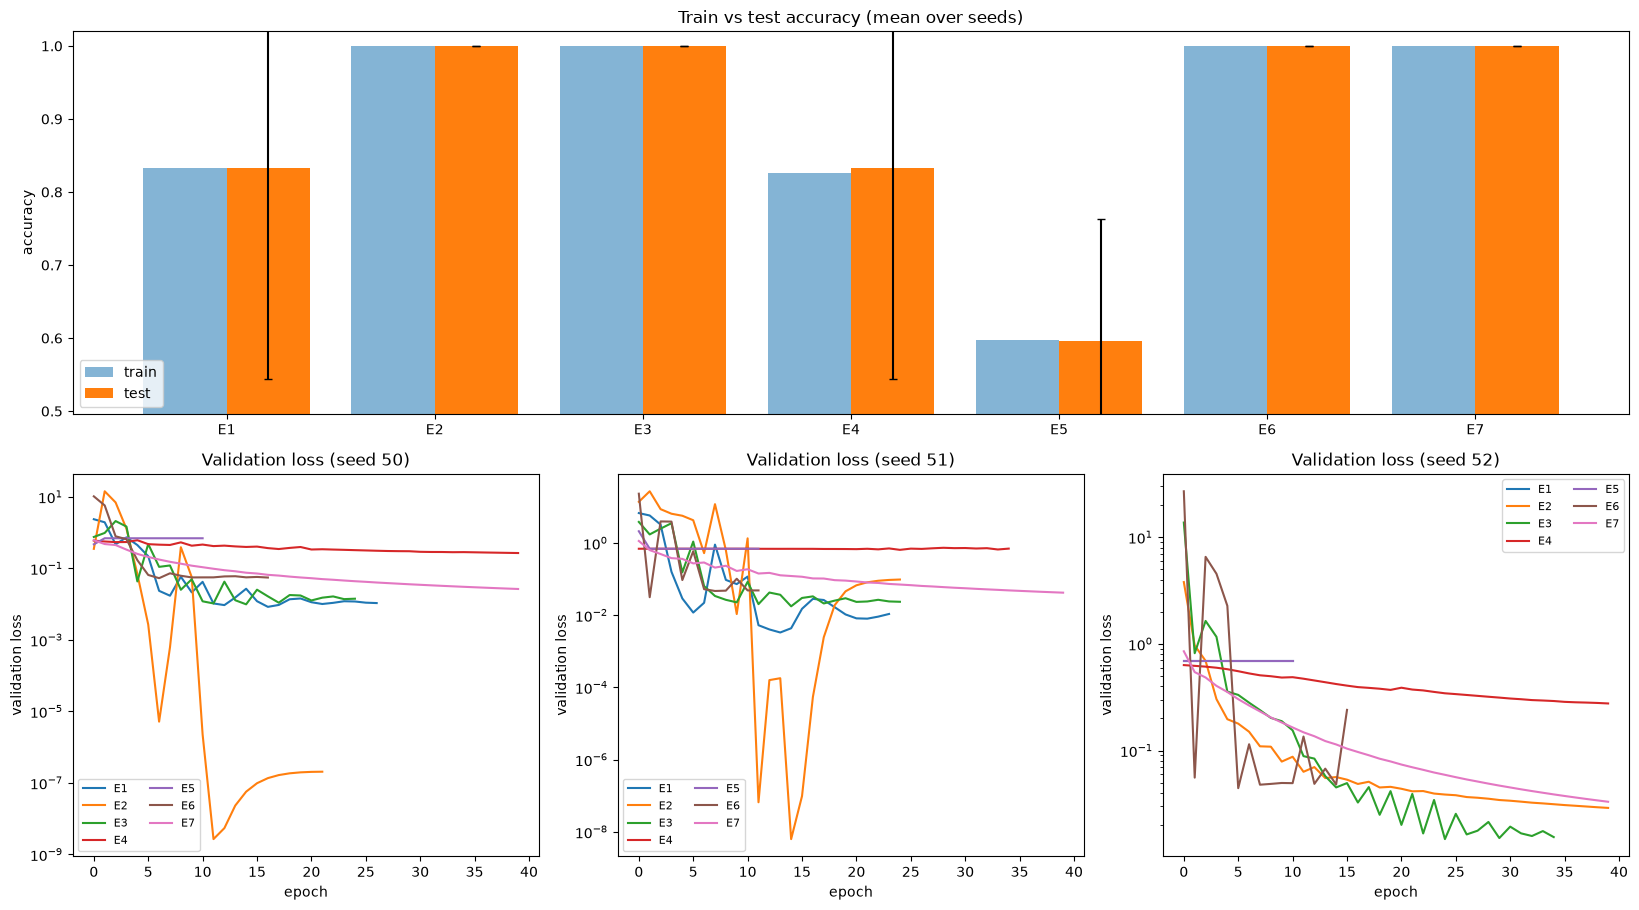

In [64]:
import math
from matplotlib.gridspec import GridSpec

seeds = list(dict.fromkeys(r["seed"] for r in RUNS))
val_per_row = 3
val_rows = max(1, math.ceil(len(seeds) / val_per_row))
n_cols = max(1, min(val_per_row, len(seeds)))
total_rows = 1 + val_rows

fig = plt.figure(figsize=(5.5 * n_cols, 4.6 * total_rows))
gs = GridSpec(total_rows, n_cols, figure=fig)

short = [n.split(":")[0].split(" ")[0] for n in summary["name"]]
xs = np.arange(len(summary))

# Row 0: train vs test accuracy spanning all columns
acc_ax = fig.add_subplot(gs[0, :])
acc_ax.bar(xs - 0.2, summary["train_acc"], 0.4, label="train", alpha=.55)
acc_ax.bar(xs + 0.2, summary["test_acc"], 0.4, yerr=summary["test_acc_std"], capsize=3, label="test")
acc_ax.set_xticks(xs); acc_ax.set_xticklabels(short)
acc_ax.set_ylim(max(0.4, summary[["train_acc", "test_acc"]].min().min() - .1), 1.02)
acc_ax.set_ylabel("accuracy"); acc_ax.set_title("Train vs test accuracy (mean over seeds)")
acc_ax.legend(loc="lower left")

# Rows 1..N: validation loss plots, up to 3 per row
for idx, seed in enumerate(seeds):
    row = 1 + idx // val_per_row
    col = idx % val_per_row
    val_ax = fig.add_subplot(gs[row, col])

    for n, lbl in zip(summary["name"], short):
        matches = [r for r in RUNS if r["name"] == n and r["seed"] == seed]
        if matches:
            val_ax.plot(matches[0]["history"]["val_loss"], label=lbl)

    val_ax.set_xlabel("epoch")
    val_ax.set_ylabel("validation loss")
    val_ax.set_yscale("log")
    val_ax.legend(ncol=2, fontsize=8)
    val_ax.set_title(f"Validation loss (seed {seed})")

plt.tight_layout()
plt.show()

### Consolidating the findings

1. **Capacity (E1 → E2 → E3)**

Increasing the number of nodes and layers raised the accuracy of the tests and training, as expected. Both E2 and E3 performed better on average, providing accurate results at the cost of time. The E2 exhibited extremely large fluctuations in validation loss in two of the tested seeds.

2. **Optimiser (E1 → E4 → E5)**

SGD performed more epochs at the same rate as baseline but with similar results. RMSprop was the fastest and had the fewest epochs in the experiment but performed the worst, which signifies that it stopped early. The validation loss curves of both tests remained largely stagnant, with the only difference being E4 in the third seed. 

3. **Regularisation (E6)**

This setup proved to be accurate, while having few epochs and a reasonable time among the rest, even though it had the most amount of parameters. At the third seed it experienced large fluctuations

4. **Input representation (E7)**

Pooling has performed the maximum amount of epochs allocated in extremely low time and with great accuracy, owing to the data being overall easy to interpret. It also provided the smoothest validation loss curve in every seed, indicating a stable learning curve.

6. **Generalisation.** The test patches come from a different part of each scene. Are there signs that the network learned the *specific* scenes you gave it (try testing on a completely new city/forest and see)?

## 6. A closer look at models' performance

The confusion matrix on the test patches shows which mistakes they make: urban patches called forest, or the other way round. The confidence plot presents how sure the model is of the patches' tag: the closer the forest patches are to 0 and the urban patches to 1, the easier they are for the model to classify properly.

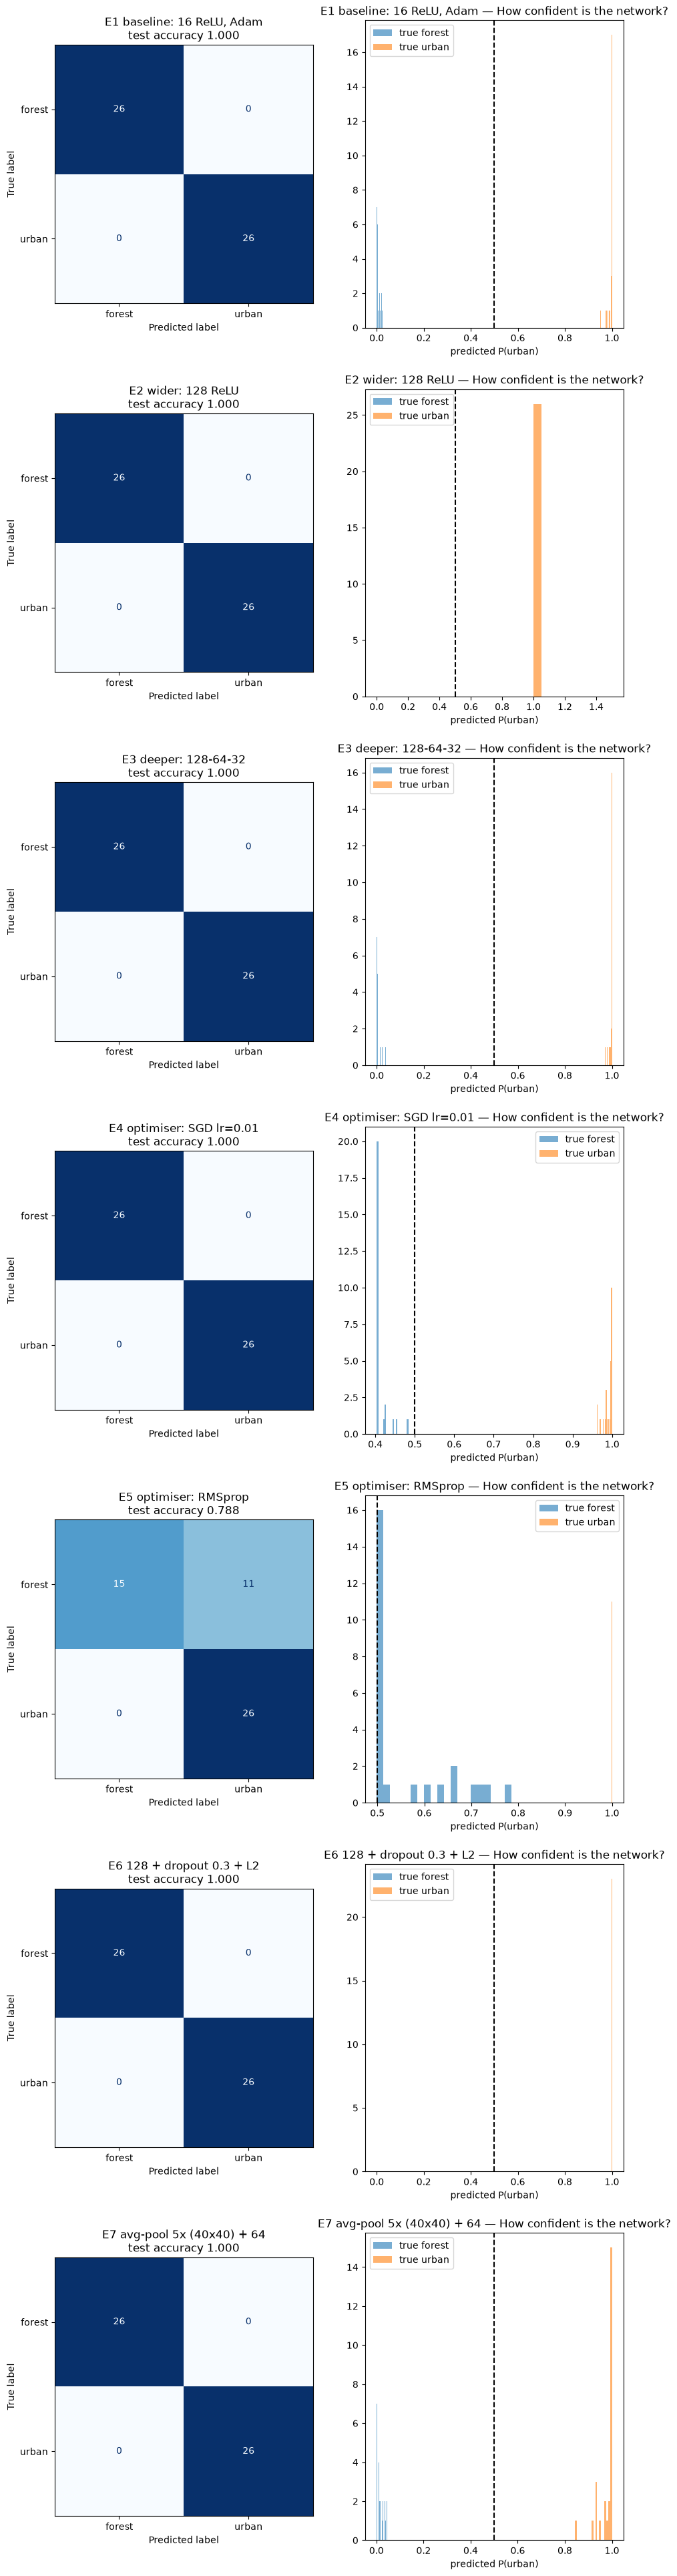

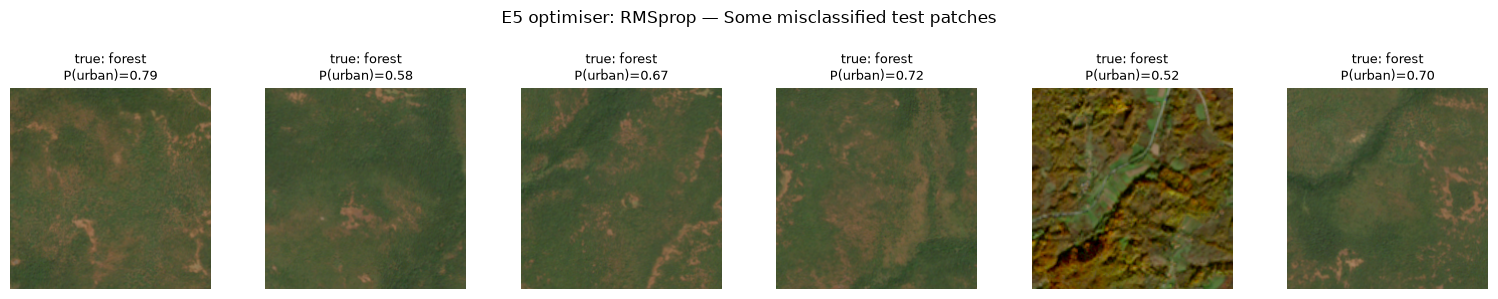

In [66]:
n_models = len(MODELS)
fig, axes = plt.subplots(n_models, 2, figsize=(11, 7 * n_models), squeeze=False)

for row, (name, model) in enumerate(MODELS.items()):
    cfg = CFGS[name]  # available if needed for model-specific post-processing/logging
    p_te = model.predict(X_te, verbose=0).ravel()
    pred = (p_te > 0.5).astype(int)

    ax_cm, ax_hist = axes[row, 0], axes[row, 1]
    ConfusionMatrixDisplay(
        confusion_matrix(y_te, pred), display_labels=CLASSES
    ).plot(ax=ax_cm, colorbar=False, cmap="Blues")
    ax_cm.set_title(f"{name}\ntest accuracy {np.mean(pred == y_te):.3f}")

    ax_hist.hist(p_te[y_te == 0], bins=20, alpha=0.6, label="true forest")
    ax_hist.hist(p_te[y_te == 1], bins=20, alpha=0.6, label="true urban")
    ax_hist.axvline(0.5, color="k", ls="--")
    ax_hist.set_xlabel("predicted P(urban)")
    ax_hist.legend()
    ax_hist.set_title(f"{name} — How confident is the network?")

    wrong = np.where(pred != y_te)[0][:6]
    if len(wrong):
        w_fig, w_axes = plt.subplots(1, len(wrong), figsize=(2.6 * len(wrong), 3), squeeze=False)
        for a, i in zip(w_axes[0], wrong):
            a.imshow(X_te[i])
            a.axis("off")
            a.set_title(f"true: {CLASSES[y_te[i]]}\nP(urban)={p_te[i]:.2f}", fontsize=9)
        w_fig.suptitle(f"{name} — Some misclassified test patches")
        w_fig.tight_layout()

plt.tight_layout()
plt.show()

The plots of E5 show that the model confuses forest patches with urban ones, wrongly assigning almost half of them. The presented miclassified samples prove to have more ground texture, which seems to not be properly accounted for by that model.

### The test phase on a whole scene

Finally, the trained functions are used to cut a fresh scene into 200 × 200 patches, find the tag of each, and paint the results as maps.

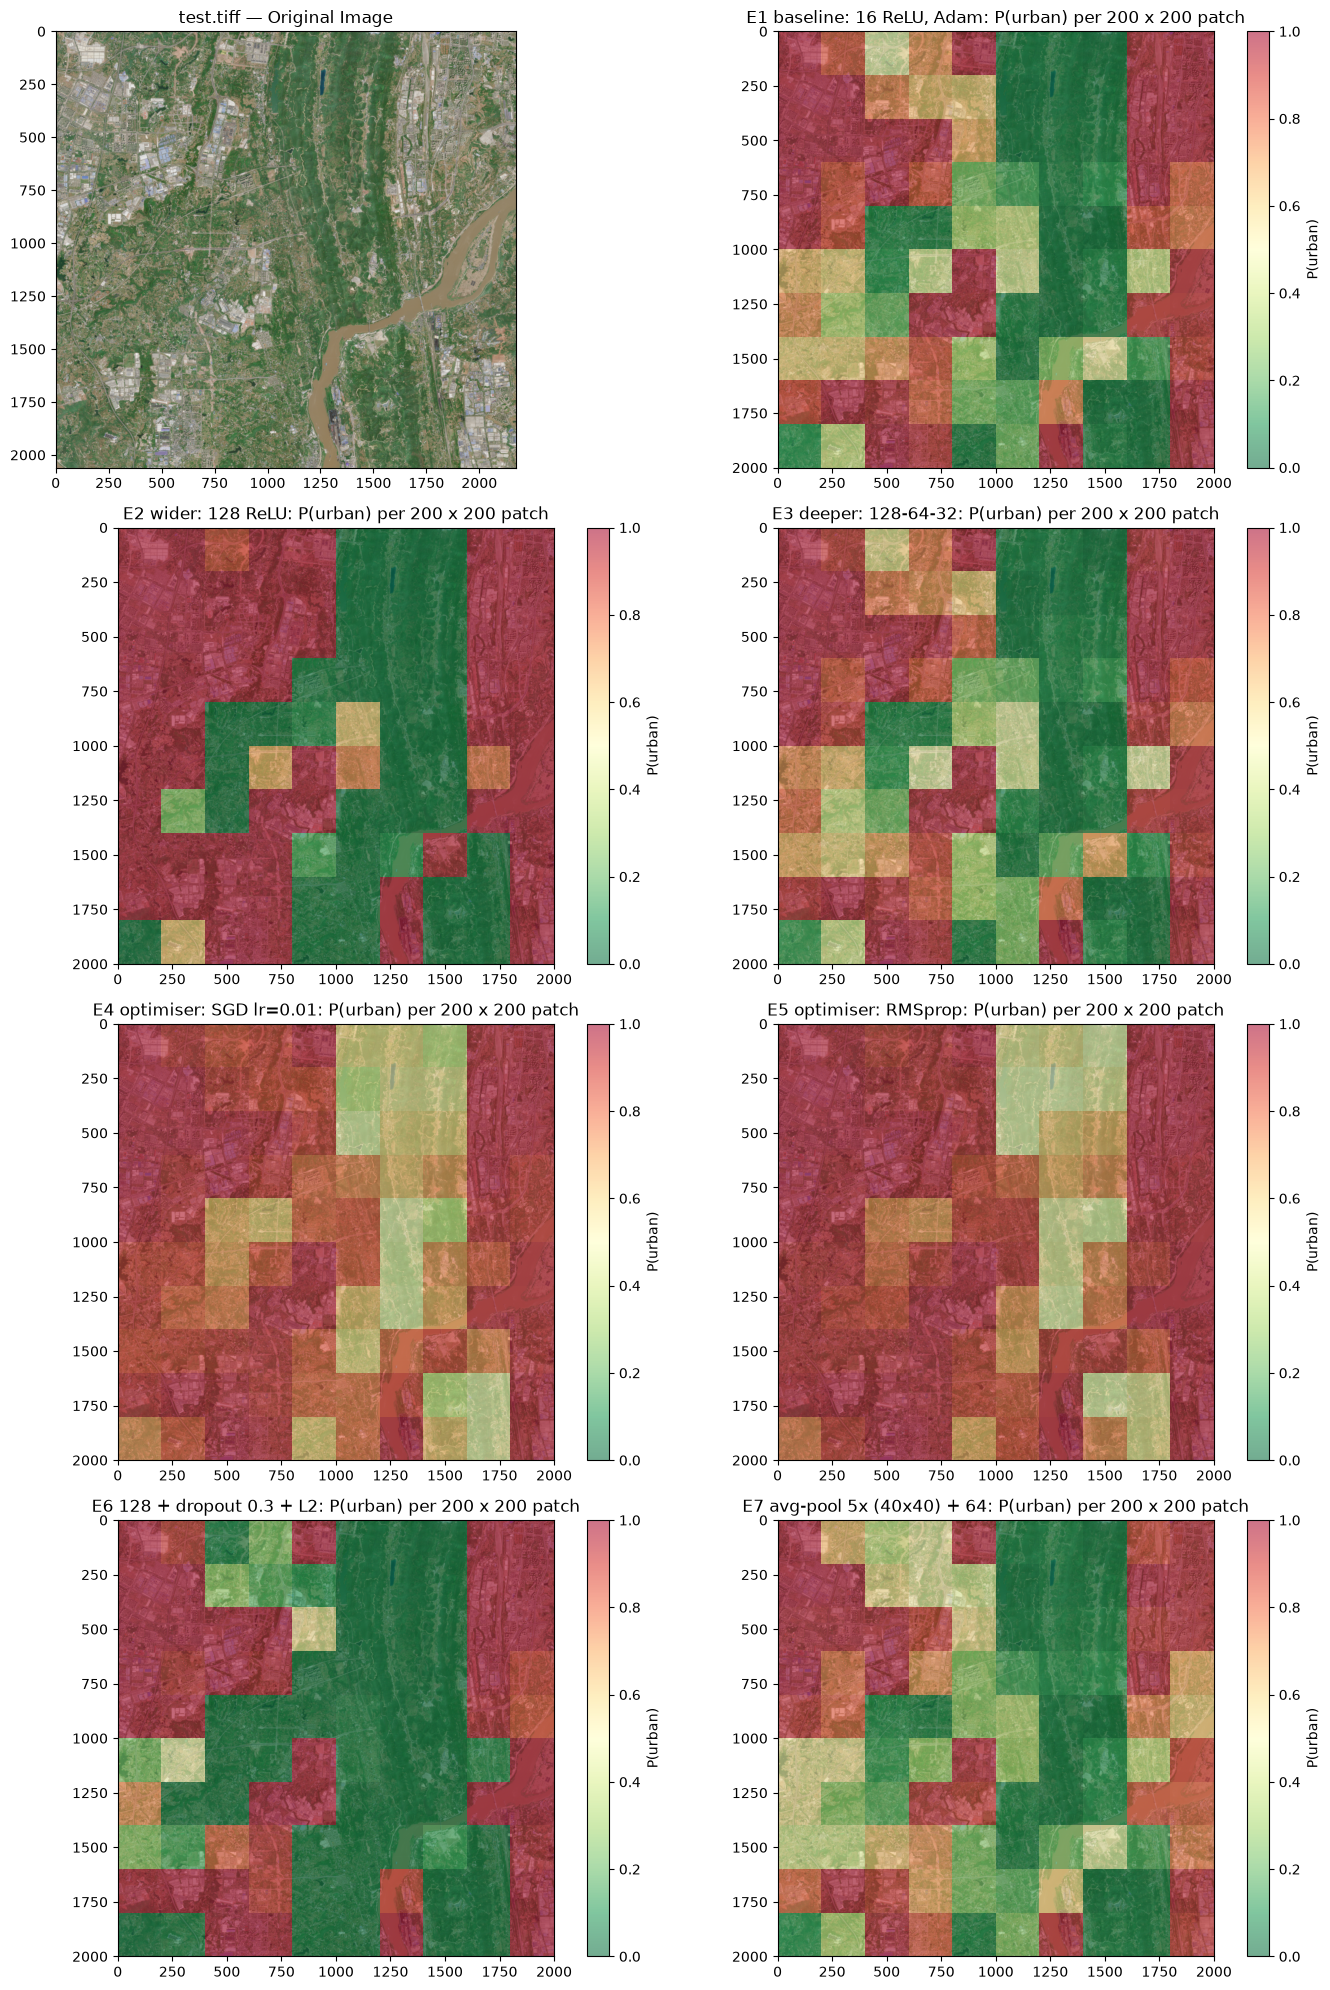

In [69]:
import math

SCENE_PATH = "data/test.tiff"

def patches_to_input(patches, cfg):
    # Return a batch of patches as input to the model, either as raw pixels or hand-crafted features.
    return np.stack(patches)

def predict_scene_from_array(img, valid, model, cfg, batch=64):
    # Return probability map for a preloaded scene image and validity mask.
    H, W, _ = img.shape
    ny, nx = H // PATCH, W // PATCH
    prob = np.full((ny, nx), np.nan)
    tiles, pos = [], []

    def flush():
        if tiles:
            p = model.predict(patches_to_input(tiles, cfg), verbose=0).ravel()
            for (j, i), v in zip(pos, p):
                prob[j, i] = v
            tiles.clear()
            pos.clear()

    for j in range(ny):
        for i in range(nx):
            sl = (slice(j * PATCH, (j + 1) * PATCH), slice(i * PATCH, (i + 1) * PATCH))
            if patch_ok(img[sl], valid[sl]):
                tiles.append(img[sl])
                pos.append((j, i))
                if len(tiles) == batch:
                    flush()
    flush()
    return prob

def predict_scene(path, model, cfg, batch=64):
    # Return (image, probability map) for a scene image at the given path.
    img, valid = load_image(path)
    return img, predict_scene_from_array(img, valid, model, cfg, batch=batch)

scene = Path(SCENE_PATH)
img, valid = load_image(scene)
H, W, _ = img.shape
s = max(1, max(H, W) // 2000)  # down-sample only for display
img_disp = img[::s, ::s]

n_models = len(MODELS)
n_rows = math.ceil((1 + n_models) / 2)
fig, axes = plt.subplots(n_rows, 2, figsize=(14, 5 * n_rows), squeeze=False)

# Slot 0: unmodified image in top-left
axes[0, 0].imshow(img_disp, extent=(0, W, H, 0))
axes[0, 0].set_title(f"{scene.name} — Original Image")

# Slots 1..n_models: model probability maps filling left-to-right, top-to-bottom
for idx, (name, model) in enumerate(MODELS.items(), start=1):
    r, c = divmod(idx, 2)
    ax = axes[r, c]
    cfg = CFGS[name]
    prob = predict_scene_from_array(img, valid, model, cfg)

    ax.imshow(img_disp, extent=(0, W, H, 0))
    im = ax.imshow(
        prob,
        extent=(0, prob.shape[1] * PATCH, prob.shape[0] * PATCH, 0),
        cmap="RdYlGn_r",
        vmin=0,
        vmax=1,
        alpha=0.55,
    )
    ax.set_title(f"{name}: P(urban) per {PATCH} x {PATCH} patch")
    plt.colorbar(im, ax=ax, fraction=0.046, label="P(urban)")

# Hide any trailing unused cell when (1 + n_models) is odd
for idx in range(1 + n_models, n_rows * 2):
    r, c = divmod(idx, 2)
    axes[r, c].axis("off")

plt.tight_layout()
plt.show()

These maps showcase how E4 and E5 perform the worst, with barely any patches classified as forest. E2 and E6 present very binary results, classifying most of the patches largely forest or urban. E1, E2 and E7 have more mixed results, although E1 most probably lacks confidence because of the fewer parameters and epochs. Personally, I would choose E7 as the most accurate representation of this map, due to the more varried assesment, fitting to the mixed nature of the image.